In [1]:
# command for starting the kernel:
# python -m pip install ipykernel -> Run in TERMINAL
# python -m ipykernel install --user --name House-Price-Predictor --display-name "House-Price-Predictor (.venv)"
# At the top right corner -> Kernel selector -> Python Environements.... -> select the last one marked with a bright big star and has the path .venv\\Scripts\\python.exe
# Verify that the notebook is really using the .venv:
# import sys
# print(sys.executable)

In [2]:
import sys
print(sys.executable)

c:\PYTHON_PRACTICE\House-Price-Predictor\.venv\Scripts\python.exe


In [3]:
# In terminal:
# pip install pandas     -> import pandas as pd   -> import numpy as np
# pip install matplotlib     -> import matplotlib.pyplot as plt
# pip install seaborn       -> import seaborn as sns
# pip install openpyxl -> for reading .xlsx files pandas needs this package

# OR DO THIS:
# pip install matplotlib seaborn scikit-learn numpy

In [ ]:
# PHASE 1: PERFORMING EDA(EXPLORATORY DATA ANALYSIS)
# HERE WE WILL USE THE fetch_california_housing OFFICIAL DATASET PROVIDED BY SCIKIT-LEARN, SO WE DONT HAVE TO DOWNLOAD ANY DATASET EXPLICITLY, SCIKIT-LEARN WILL DOWNLOAD THE DATASET FOR YOU AND LOAD IT INTO A PANDAS DATAFRAME.
# we can retrieve that dataset by importing the Scikit-learn function: fetch_california_housing .

In [5]:
# IMPORT LIBRARIES:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.datasets import fetch_california_housing


In [6]:
# Loading the dataset:
# first we check of the dataset is already available in Scikit-learn's data cache -> if YES = Scikit-learn loads it -> if NO = Scikit-learn downloads it automatically


housing = fetch_california_housing(as_frame=True) # as_frame=True -> ensures that the data is provided in pandas frendly format

# Storing the loaded dataset in a dataframe "df":

df = housing.frame


In [7]:
# saving a copy of the csv data in the project folder:
df.to_csv("data/california_housing.csv", index = False)

In [8]:
# ACTION 1-----
# INVESTIGATING THE DATASET

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [9]:
# Checking dataset dimensions (number of rows and columns)
df.shape

(20640, 9)

In [10]:
# Viewing the column names:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')

In [11]:
# checking the data types of each column:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [12]:
# Checking and counting the number of missing values in each column:

df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [13]:
# checking the number of duplicate column values:
df.duplicated().sum()

np.int64(0)

In [14]:
# Statistical summary of each numerical column:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


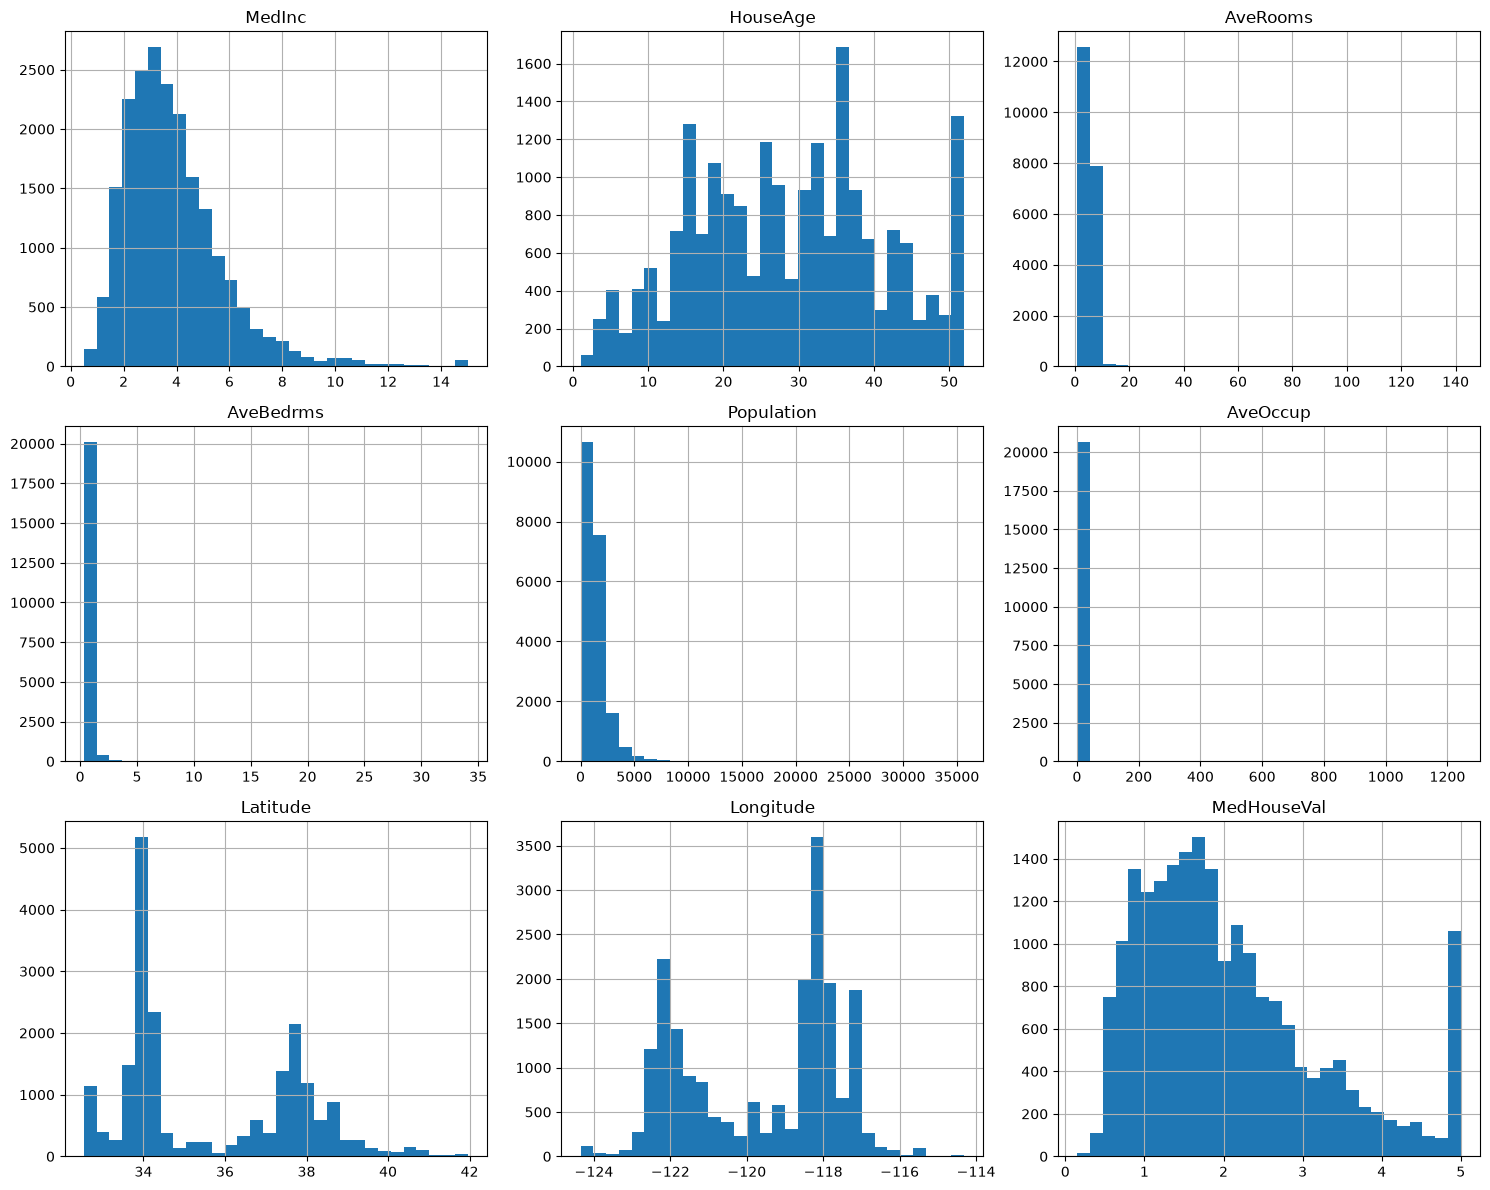

In [15]:
# ACTION 2-----
# visualizing the dataframe using histograms to understand the patterns:
# Creating histograms for each numeric column in the dataframe
df.hist(
    figsize = (15,12),
    bins = 30
)
plt.tight_layout()
plt.show()

In [16]:
# Analysis of the Ststistical summary and Histograms:

# 1. MedInc ->
# min = 0.50 median income
# max = 15.00 median income
# Most districts have income concentrated between 2 and 5
# the tallest bars are around 3
# X-axis: Median income of households in each district, measured in tens of thousands of US dollars.
# Y-axis: Number of districts within each income interval.
# The distribution is right-skewed: mean > median 
# As most districts have incomes ranging from 1 to 5, and very few districts are able to reach the income beyond 5 upto 15.
# the maximum median income is around $150,000.

# 2. HouseAge ->
# min = 1 year
# max = 52 years
# X-axis: Median house age in each district, measured in years.
# Y-axis: Number of districts within each house-age interval.
# Many districts have median house ages between approximately 15 and 40 years.

# 3. AveRooms ->
# min = 6.05 rooms per household in each district
# max = 141 rooms per household in each district
# X-axis: Average number of rooms per household in each district.
# Y-axis: Number of districts within each room-count interval.
# the distribution is right-skewed
# Most of the districts have a few number of rooms per household from 2 to 8 rooms (on x axis)
# Very few (about 100 districts on the y axis) extend beyound the ordinary room count and go upto 20 on the X axis

# 4. AveBedrms ->
# min = 1.10 bedrooms per household in each district
# max = 34 bedrooms per household in each district.
# X-axis: average number of bedrooms per household in each district
# Almost all households in districts have about 0 to 1 rooms each
# Distribution is Right-skewed.


# 5. Population -> Total district population
# min = 1725 population per household in each district
# max = 35682 population per household in each district
# X-axis: Total population recorded for each district.
# Y-axis: Number of districts within each population interval.
# the distribution is right-skewed because the mean is higher than the median
# Almost all districts have population below 2000


# 6. AveOccup — Average household occupancy -> Average number of people per househol in a district
# min = 3.28 => 3 to 4 people per household in the district
# max = 1243 people per household in the district -> this is an extreme value compared to the median of 2.82 -> as a result of this nearly all observations are concentrated near the left side.
# This concentration makes the distribution extremely right-skewed.


# 8. MedHouseVal - Median house value
# min = 0.15
# max = 5.00
# mean > median -> histogram is right-skewed


# the histograms that are right-skewed are so because, because the x-axis values did not extend far enoiugh to include the extreme values, as a result the majority of the observations are compressed towards the left.



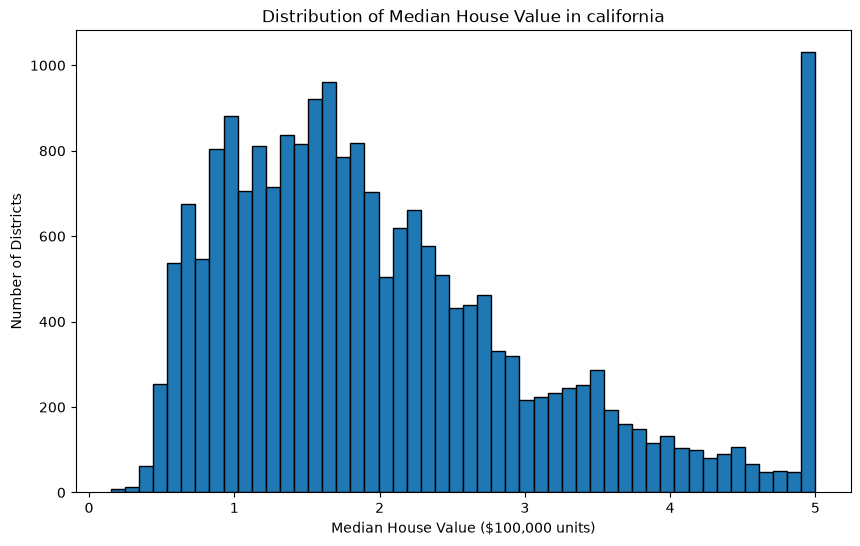

In [17]:
# ACTION 3----
# Examining the distribution of the target column MedHouseVal
# Uour model will learn to predict the MedHouseVal value, so we try to understnd it in detail
# creating a histogram for this column

plt.figure(figsize =(10, 6))
plt.hist(
    df["MedHouseVal"],
    bins = 50,
    edgecolor = "black"
)

plt.title("Distribution of Median House Value in california")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Number of Districts")
plt.show()

In [18]:
# Here the x-axis actually represents:
# 1 = $100,000
# 2 = $200,000
# 3 = $300,000
# 4 = $400,000
# 5 = $500,000

# ANALYSIS:
# most of the districts in California have house values concentrated around 1($ 100,000) and 2($200,000) 
# As values increase beyond $200,000, the number of districts drops gradually creating a long tail to the right, until the bar rises again at $500,000 value.
# the rising vertical bar at 5 median house value, indicates capped data:
# this means that if the house values were, $600,000, $1000,000, or more, it was simply recorded as $500,000, because that os the upper limit set by the data collectors, and no value can cross that limit and just sits within that.


# effect of capped value on the model:
# The model may struggle to predict the true values of districts whose actual median house values exceed $500,000 because the training data does not contain those uncapped target values.

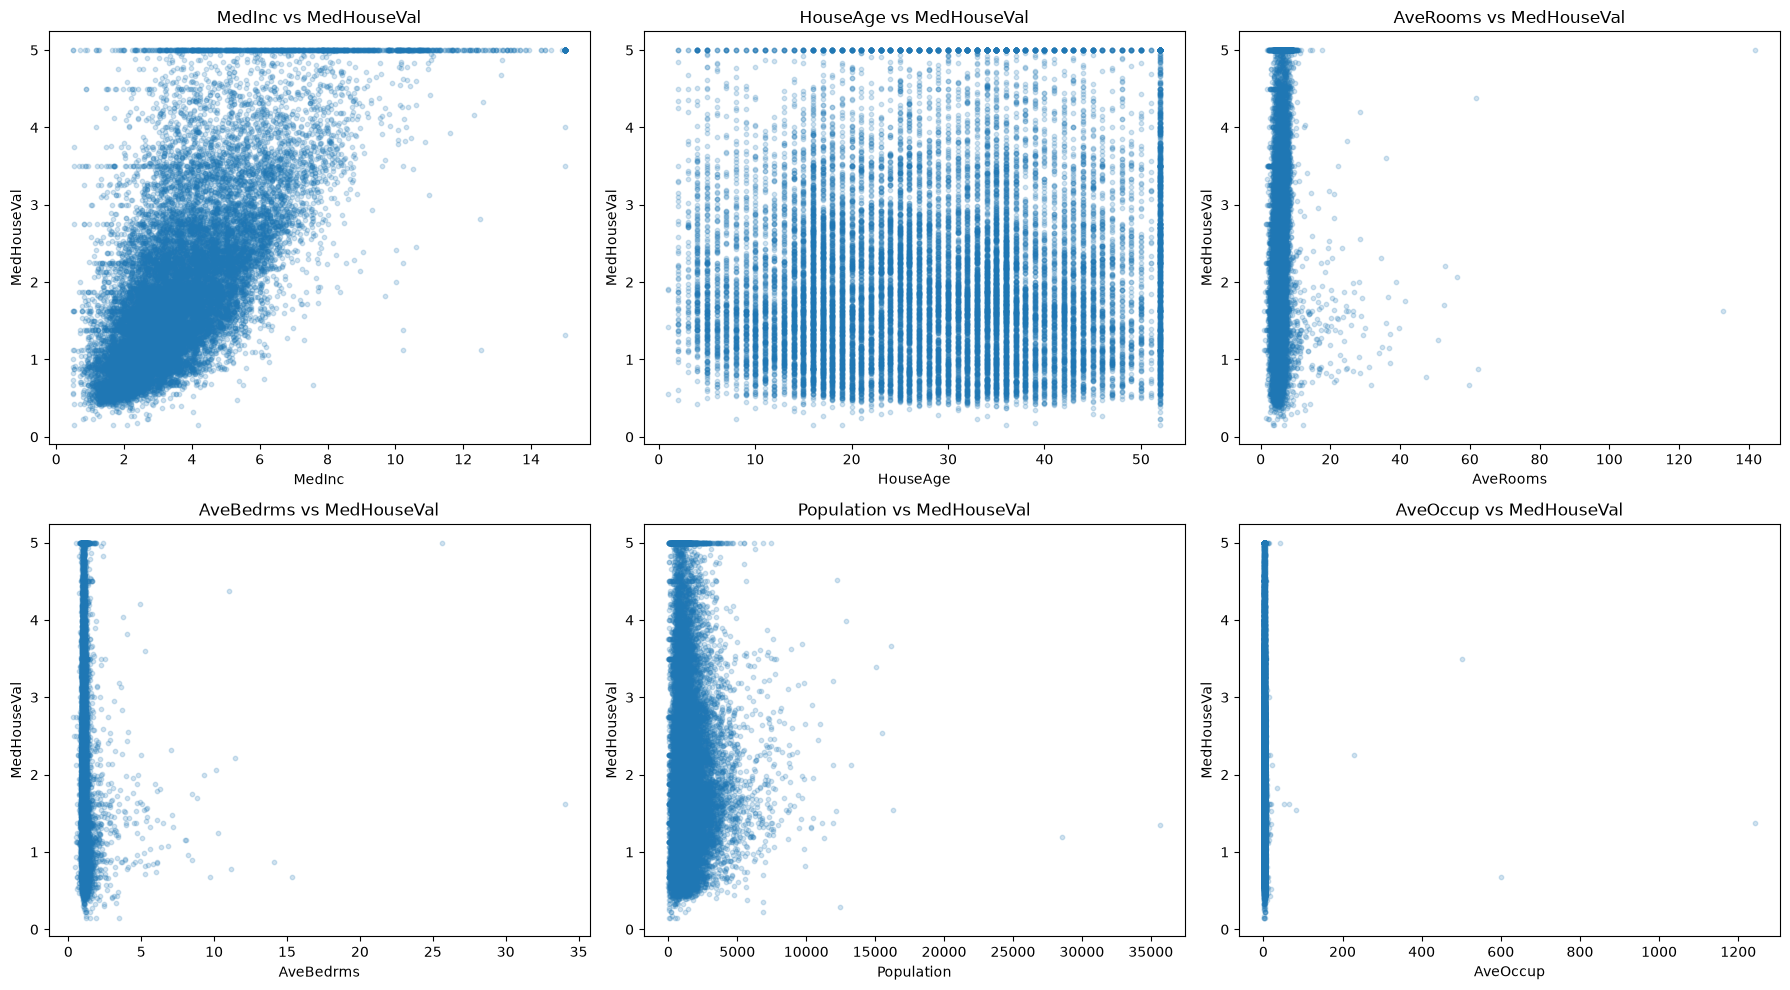

In [19]:
# ACTION 4----
# Investigating the relationship between individual features and the target.
# Here we see how the remaining input features relate to the target feature MedHouseVal, using Scatter plots:

features = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10)
)

for ax, feature in zip(axes.flatten(), features):
    ax.scatter(
        df[feature],
        df["MedHouseVal"],
        alpha=0.2,
        s=10
    )

    ax.set_title(f"{feature} vs MedHouseVal")
    ax.set_xlabel(feature)
    ax.set_ylabel("MedHouseVal")

plt.tight_layout()
plt.show()

In [20]:
# ANALYSIS:


# 1. MedInc vs MedHouseVal:
# As median income increases the house values also increase -> this shows a strong linear trend.
# The horizontal line running along the x axis at y = 5, confirms the $500,000 price capping across all house incomes.

# 2. MedHouseVal vs HouseAge
# Shows no slope or correlation as the values are evenly spread across all house Ages.
# The vertical line runnig along the y axis at x = 52 confirms the 52 age capping across all house ages.

# In all the remaining 4 plots -> AveRooms vs MedHouseVal, AveBedrms vs MedHouseVal, Population vs MedHouseVal, and AveOccup vs MedHouseVal, almost every data point is squished into a narrow vertical band near zero because of a few massive extreme outliers on the x-axis. These extreme outliers make it impossible to see the underlying pattern for normal districts on a standard scale

In [21]:
# ACTION 5----
# Calculating the Correlation matrix -> calculatng the correlations across all numeric columns at once.

correlation_matrix = df.corr(numeric_only =True)
correlation_matrix
 

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


In [22]:
# Examining the correlation of the following columns with MedHouseVal:
# 1. MedInc = 0.688075 -> Strong positive (closer to 1) -> the variables move in the same direction together.
# 2. HouseAge = 0.105623 -> weak positive (closer to 0) -> the variables move in the same direction
# 3. AveRooms = 0.151948 -> weak positive (closer to 0) -> the variables move in the same direction
# 4. AveBedrms = -0.046701 -> Very weak negative linear relationship. 
# 5. Population = -0.024650 -> Very weak negative linear relationship.
# 6. AveOccup = -0.023737 -> Very weak negative linear relationship.
# 7. Latitude = -0.144160 -> Weak negative linear relationship.
#  Longitude = -0.045967 -> Weak negative linear relationship.

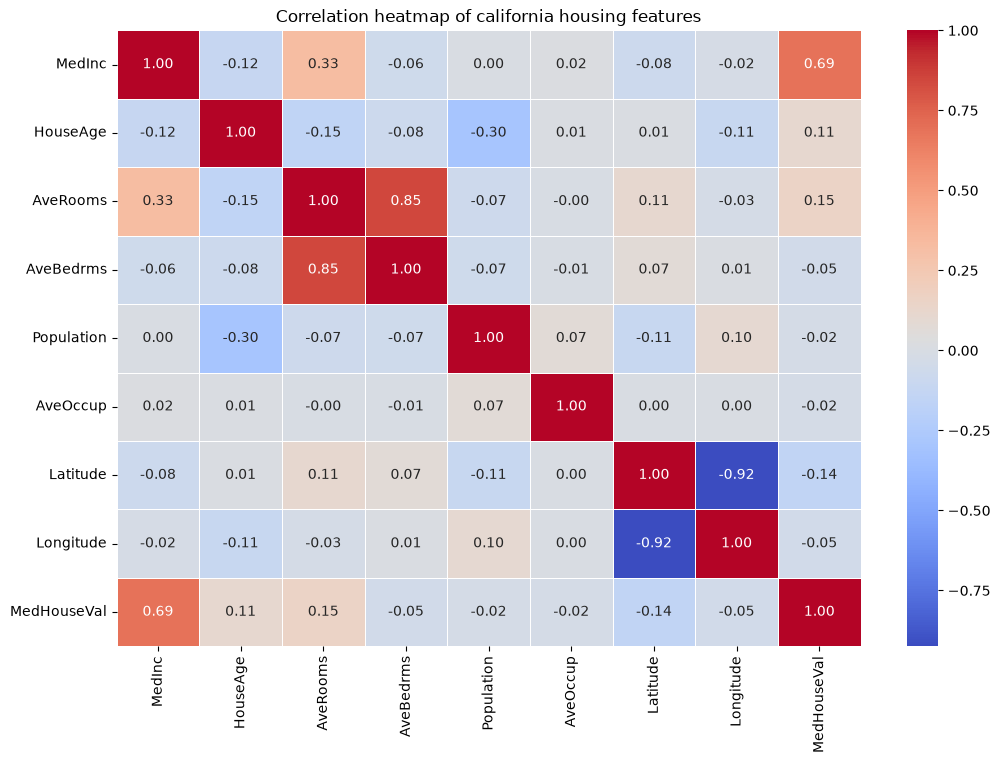

In [23]:
# ACTION 6----
# Visualizing the correlation matrix using a heatmap:
plt.figure(figsize=(12,8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation heatmap of california housing features")
plt.show()

In [24]:
# ANALYSIS: 
# 1. MedInc vs MedHouseVal -> 0.69 = strong positive relationship
#-> neighborhoods where people earn higher incomes -> these neighborhoods have houses that cost high 

# 2. AveRooms vs MedHouseVal -> 0.15 = positive realtionship
# -> with increase in the number of rooms in a house -> the price of the house also increases.

# 3. AveBedrms vs AveRooms -> 0.85 = strong positive relationship
# -> houses with more number of bedrooms have more number of total rooms in the house.

# 4. Latitude vs Longitude -> -0.92 = Extreme negative relationship
# -> As latitude increases (as we move towards north) -> Longitude decreases (we move towards west)

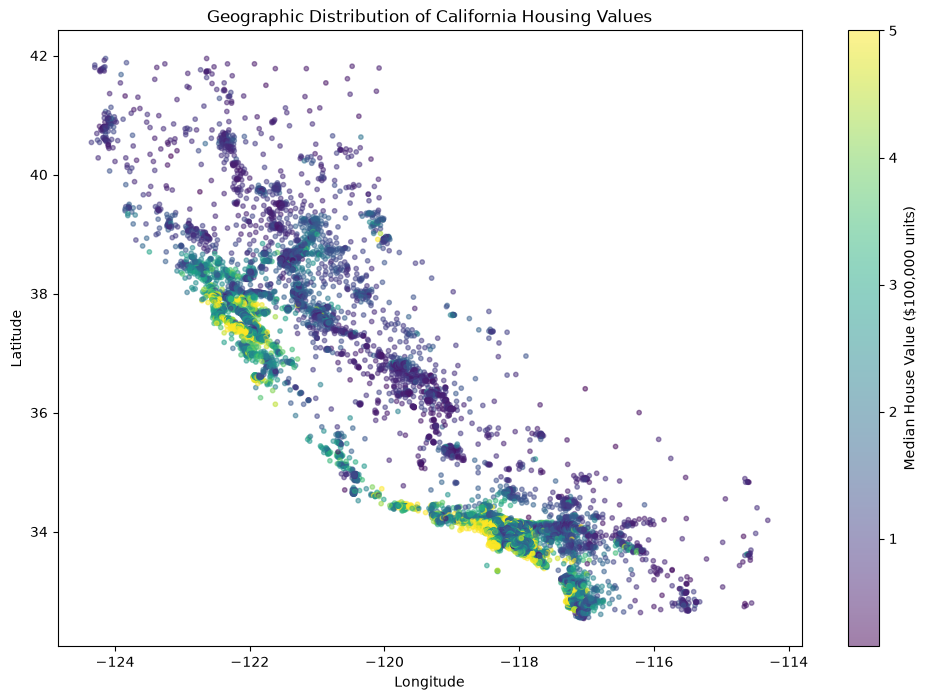

In [25]:
# ACTION 7----
# Housing values are often influenced by their location
# Here we are examining how the latitudes and longitudes influence the housing prices

# Building a scatter plot:
plt.figure(figsize=(12, 8))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"], # the color of each dot is determined by the MedHouseVal column values -> each point gets coloured according to its house value.
    cmap="viridis",
    alpha=0.5,
    s=10
)

# cmap -> colormap
# viridis -> a popular gradient palette that transitions from dark purple (low values) through blue and green to bright yellow (high values).

plt.colorbar(label="Median House Value ($100,000 units)")

plt.title("Geographic Distribution of California Housing Values")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [26]:
# ANALYSIS:
# X-Axis: longitude -> -124 to -114
# Y-Axis: Latitude -> 34 to 42
# color scale: determined by the MedHouseVal (median house value):
    # Dark purple -> represents lower Median house values -> < 1 ($100,000)
    # Green -> represents moderate house values -> 2 to 3 ($200,000) to ($300,000)
    # yellow -> represents high house values -> 4 to 5

# DATA INSIGHTS:
# CLUSTERING: 
# areas where most of the points overlap appear darker.
# This clustering of the yellow, green and purple data points happens at around latitudes 34 and 38

# 1 Yellow dots = hight house values:
# these dots are clustered in 2 distinct locations:
    # Latitude 34 and Longitude -118
    # Latitude 38 and Longitude -122

# As you move to higher longitudes from -124 to -114 on the x-axis -> the data points turn dark purple



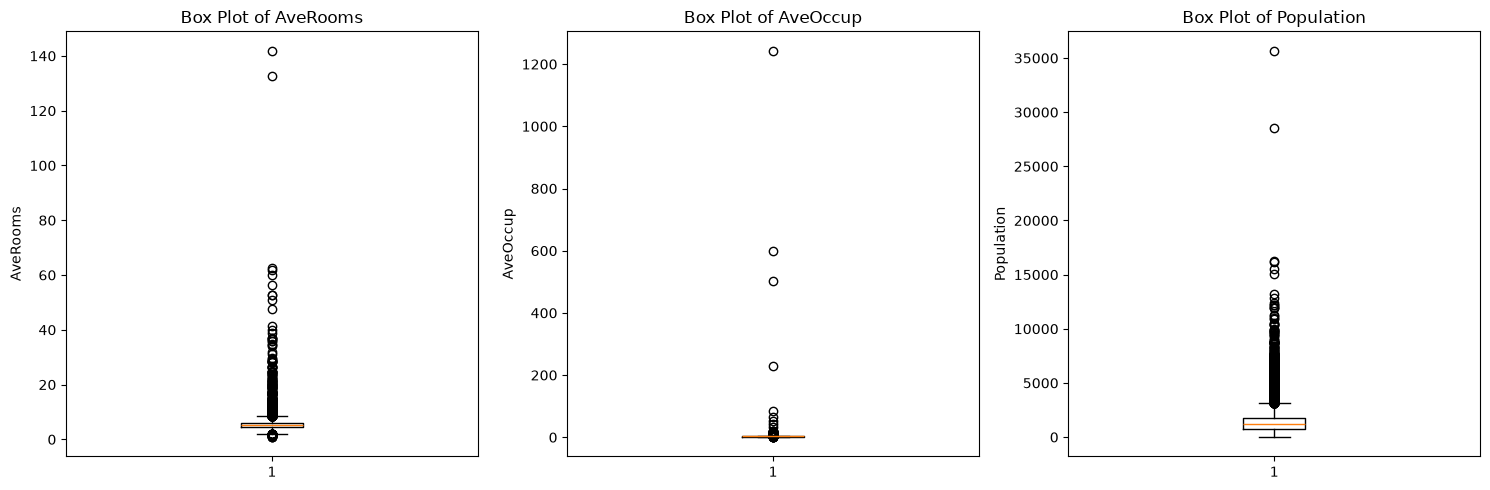

In [27]:
# ACTION 8-----
# Investigating the outliers using Box plots:
features_to_check = [
    "AveRooms",
    "AveOccup",
    "Population"
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 5)
)

for ax, feature in zip(axes, features_to_check):
    ax.boxplot(df[feature])

    ax.set_title(f"Box Plot of {feature}")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

In [28]:
# BOX PLOT ANALYSIS:

# The Orange Line -> 
# shows the median or 50th percentile of the dataset
# 50% of the datavalues fall below this oranghe line and 50% of them are above the line

# the Box ->
# represents the inter quartile range (IQR)
# it shows the data values bounded by the 25th Percentile [Bottom side of the box] and the 75th precentile [Top side of the Box]
# Data inside the top and bottom sides of the box is the interquartile range.
# If the box is flat or squished = the top and bottom side are compressed against each other -> data values inside the box are tightly packed together

# Whiskers ->
# upper and lower whiskers form the range of normal values in the dataset

# Outliers ->
# circles lying above the upper whisker and below the lower whisker are considered as OUTLIERS


# ANALYSING EACH BOX PLOT:

# Box Plot of AveRooms:
# the normal data sits between the upper whisker and lower whisker,  around 2 to 9 rooms per household.
# 50 % MIddle Data -> data inside the box -> the box and the orange line are compressed together -> meaning the 50% of the data is around 3 to 8 rooms per household
# MILD OUTLIERS: There is a high concentration of circles at around 10 to 40 rooms per household -> these are mild outliers -> they may not represent the average room count in a regular household, but the room count of residential buildings like vacation homes, luxuru estates, etc.
# EXTREME OUTLIERS: the circles floating beyond the concentrated area are extreme outliers -> they might result from anomalies or data errors.

# Box Plot of AveOccup:
# the normal sits around 1 to 5.
# MILD OUTLIERS: there is a concentration of circles extending upto an average of 100 people in a household, beyond the normal range of people.
# EXTREME OUTLIERS: The circles floating away from the concentrated areas, shooting up to 200 and over 1200 people in a household -> this might result from a data error!

# Box plot of Population:
# Middle 50% Data -> data inside the box -> the moiddle 50% of the population sits approximately below 1700 people per household
# Orange line -> this shows the median district population -> around 1000 people per household.
# MILD OUTLIERS: there is a concentration of poluation extending beyoud the approximate normal population of 3500 all the way upto 13500 (approx.) -> this strength might cover the high desinsity areas of a district such as downtowns.
# EXTREME OUTLIERS: The two isolated circles floating from approximately 27000 population count to over 35000 population count with large empty gaps beneath them are the extreme outliers -> they might result from anomalies and data errors.

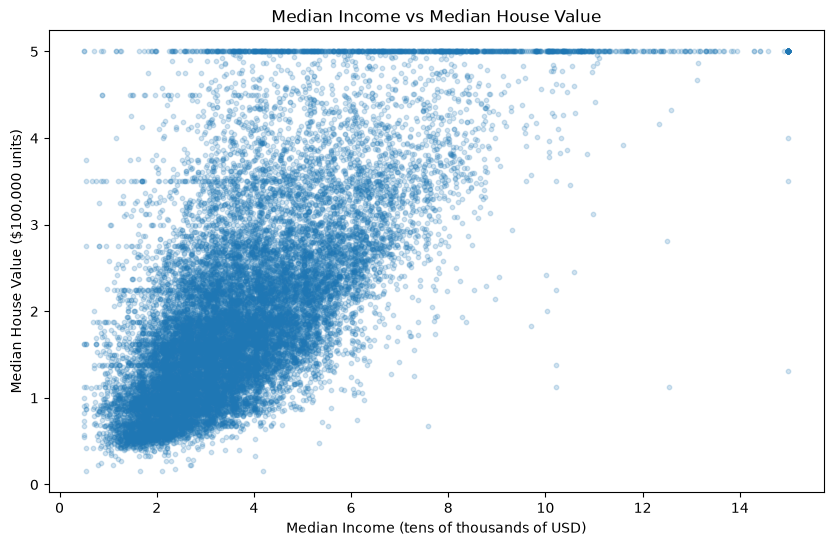

In [29]:
# action 9----
# Investigating the relationship between income and median house value in greater detail

plt.figure(figsize=(10, 6))

plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.2,
    s=10
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income (tens of thousands of USD)")
plt.ylabel("Median House Value ($100,000 units)")

plt.show()

In [ ]:
# ANALYSIS:
# earlier in the heatmap we analysed that the median income and median house value have a strong positive correlation/relationship -> neighborhoods whare people earn higher income are those neighborhoods where the house prices are often more higher.

# In this scatterplot we see a very strong positive trend shown by an upward slope from left to right -> meaning: as median income increases in a neighborhood, the median house value also goes up
# LIMITATION -> There is a cap at Median House Value = 5, meaning that the data collector has set 5 as the limit of the house values at $500,000, and any value greater than that was still recorded as exactly $500,000